# Error Analysis

The error analysis is divided into three parts, the first of which examines the overlap between BM25 and dense search. Its objective is to determine the extent to which BM25 and dense search retrieve the same products, and what occurs within RRF when the same products are not found.

The second part identifies the specific stage at which the pipeline fails.

The third part covers the manual classification of top-1 errors.


Manual classification of the top 1 results that failed

Provide: Error Categories in the Report

BM25: "6-koloruuvi" vs, "kuusiokoloruuvi"

In [2]:
# libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## BM25 and Dense overlapping

The Cross-Encoder log was not run in the 7th notebook, so we will run it here.

In [3]:
# dev set
dev = pd.read_csv('../data/clean/test_set_dev.csv', dtype={'gold_product_number': str})
dev_queries = dev.groupby('clean_query').agg({
    'gold_product_number': lambda x: set(str(p) for p in x),
    'product_label': 'first',
    'area_name': 'first'
}).reset_index()

In [4]:
# BM25 and dense search results
bm25_df = pd.read_csv('../data/clean/bm25_stem_top100_dev.csv', dtype={'product_number': str})
dense_df = pd.read_csv('../data/clean/dense_e5_top100_dev.csv', dtype={'product_number': str})

bm25_top20 = bm25_df[bm25_df['rank'] <= 20]
dense_top20 = dense_df[dense_df['rank'] <= 20]

In [ ]:
# overlap analysis
overlap_records = []

for q in dev_queries['clean_query']:
    bm25_prods = set(bm25_top20[bm25_top20['clean_query'] == q]['product_number'])
    dense_prods = set(dense_top20[dense_top20['clean_query'] == q]['product_number'])
    
    common = bm25_prods & dense_prods # AND
    union = bm25_prods | dense_prods # OR
    
    overlap_records.append({
        'clean_query': q,
        'common_count': len(common),
        'jaccard_similarity': len(common) / len(union) if union else 0.0,
        'zero_overlap': len(common) == 0
    })

df_overlap = pd.DataFrame(overlap_records)

print(f"Average common products in top-20: {df_overlap['common_count'].mean():.2f}")
print(f"Jaccard Similarity (Average): {df_overlap['jaccard_similarity'].mean():.3f}")
print(f"Queries with 0 overlapping products in dev set: {df_overlap['zero_overlap'].sum()} ({df_overlap['zero_overlap'].mean()*100:.1f} %)")

Average common products in top-20: 2.91
Jaccard Similarity (Average): 0.089
Queries with 0 overlapping products in dev set: 33 (24.3 %)


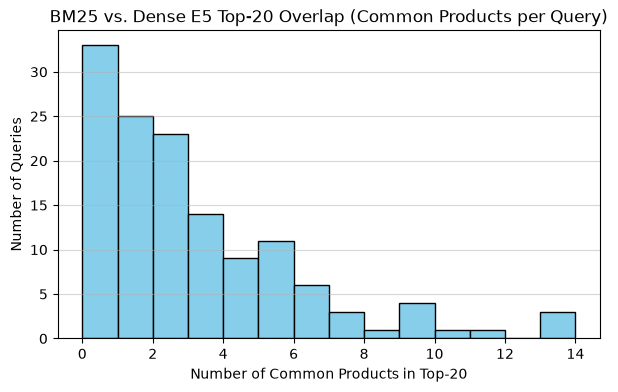

In [9]:
plt.figure(figsize=(7, 4))
plt.hist(df_overlap['common_count'], bins=range(0, 15), edgecolor='black', color='skyblue')
plt.title('BM25 vs. Dense E5 Top-20 Overlap (Common Products per Query)')
plt.xlabel('Number of Common Products in Top-20')
plt.ylabel('Number of Queries')
plt.grid(axis='y', alpha=0.5)
plt.show()

* Out of 20 products, on average only 2.9 are the same.
* Jaccard Similarity (0-1): 0.089 , BM25 and Dense mostly find different products.
    * BM25 finds very precise codes and measurements.
    * Dense searches at a more general conceptual level, but loses the numbers and sizes.
* In 33 queries (24.3%), BM25 and Dense did not share any common products.
    * Impact on the RRF:
        * RRF works best when the same product appears on both lists, in which case it receives double points.
        * When the score is zero, both receive the same points, resulting in a tie. In such cases, RRF interleaves the items by alternating between them; however, since BM25 is added to the list first in the code, BM25 wins the tie. RRF doesn't know who has more correct guesses.

This may explain why the Cross-Encoder improves the result so much. It acts as a referee.

"6-koloruuvi" vs, "kuusiokoloruuvi"

There are two different way to label "kuusiokoloruuvi".

"6" = "kuusio"

-> BM25 does not find differences in between top 5 products.

(test function in retreivers)

The system only recognizes specific product names, but it can see the hierarchy above that.

BM25 is blind to synonyms, but it is fast.

Reminder for error analysis: for the query “kuusiokoloruuvi din7984 a4 m8x40”, the BM25 and dense top 20 lists had no products in common, so RRF only interleaved them and BM25 won every tie because its results are added first. Check how often the lists do not overlap on the dev set, because in those cases hybrid Hit@1 simply equals BM25 Hit@1. The query also shows an abbreviation problem: the catalog writes “6-koloruuvi”, so the correct product gets zero points for “kuusiokoloruuvi” while products that use the full word in their description get extra points.

## Pipeline funnel

Where pipeline fails..

In [12]:
# load all results of the pipeline

dev = pd.read_csv('../data/clean/test_set_dev.csv', dtype={'gold_product_number': str})
dev_queries = dev.groupby('clean_query').agg({
    'gold_product_number': lambda x: set(str(p) for p in x),
    'product_label': 'first',
    'area_name': 'first'
}).reset_index()

bm25_top20 = pd.read_csv('../data/clean/bm25_stem_top100_dev.csv', dtype={'product_number': str})
bm25_top20 = bm25_top20[bm25_top20['rank'] <= 20]
dense_top20 = pd.read_csv('../data/clean/dense_e5_top100_dev.csv', dtype={'product_number': str})
dense_top20 = dense_top20[dense_top20['rank'] <= 20]
hybrid_top20 = pd.read_csv('../data/clean/hybrid_rrf_top20_dev.csv', dtype={'product_number': str})
reranked_top20 = pd.read_csv('../data/clean/reranked_top20_dev.csv', dtype={'product_number': str})
llm_log = pd.read_csv('../data/clean/rag_selection_log_qwen3.5_9b.csv', dtype={'chosen_code': str})

In [16]:
# trace the pipeline for each query
funnel_records = []

for _, row in dev_queries.iterrows():
    q = row['clean_query']
    gold = row['gold_product_number']
    
    b20 = set(bm25_top20[bm25_top20['clean_query'] == q]['product_number'])
    d20 = set(dense_top20[dense_top20['clean_query'] == q]['product_number'])
    h20 = set(hybrid_top20[hybrid_top20['clean_query'] == q]['product_number'])

    ce_rank1 = reranked_top20[(reranked_top20['clean_query'] == q) & (reranked_top20['rank'] == 1)]
    ce_hit1 = any(p in gold for p in ce_rank1['product_number']) if not ce_rank1.empty else False

    llm_row = llm_log[llm_log['clean_query'] == q]
    llm_hit1 = llm_row['is_hit'].values[0] if not llm_row.empty else False

    funnel_records.append({
        'clean_query': q,
        'area_name': row['area_name'],
        'gold_label': row['product_label'],
        'in_bm25_top20': any(p in gold for p in b20),
        'in_dense_top20': any(p in gold for p in d20),
        'in_hybrid_top20': any(p in gold for p in h20),
        'ce_hit1': ce_hit1,
        'llm_hit1': llm_hit1
    })

df_funnel = pd.DataFrame(funnel_records)

In [17]:
# funnel statistics
n_total = len(df_funnel)
retrieved_count = df_funnel['in_hybrid_top20'].sum()
retrieval_fail = n_total - retrieved_count

ce_hits = df_funnel['ce_hit1'].sum()
ce_rank_fail = retrieved_count - ce_hits

llm_hits = df_funnel['llm_hit1'].sum()
llm_fail = retrieved_count - llm_hits

In [23]:
print(f"Total queries: {n_total} (100 %)")
print(f"1. Search Stage: {retrieved_count} ({retrieved_count/n_total*100:.1f} %)")
print(f"   -> Failed in Search Stage (Retrieval): {retrieval_fail} ({retrieval_fail/n_total*100:.1f} %)")

print(f"2. Cross-Encoder Hit@1:  {ce_hits}  ({ce_hits/n_total*100:.1f} %)")
print(f"   -> Failed in Reranking Stage (Ranking): {ce_rank_fail} ({ce_rank_fail/n_total*100:.1f} %)")

print(f"3. LLM Selection Hit@1:  {llm_hits}  ({llm_hits/n_total*100:.1f} %)")
print(f"   -> Failed in LLM Selection Stage (Selection): {llm_fail} ({llm_fail/n_total*100:.1f} %)")

Total queries: 136 (100 %)
1. Search Stage: 81 (59.6 %)
   -> Failed in Search Stage (Retrieval): 55 (40.4 %)
2. Cross-Encoder Hit@1:  45  (33.1 %)
   -> Failed in Reranking Stage (Ranking): 36 (26.5 %)
3. LLM Selection Hit@1:  31  (22.8 %)
   -> Failed in LLM Selection Stage (Selection): 50 (36.8 %)


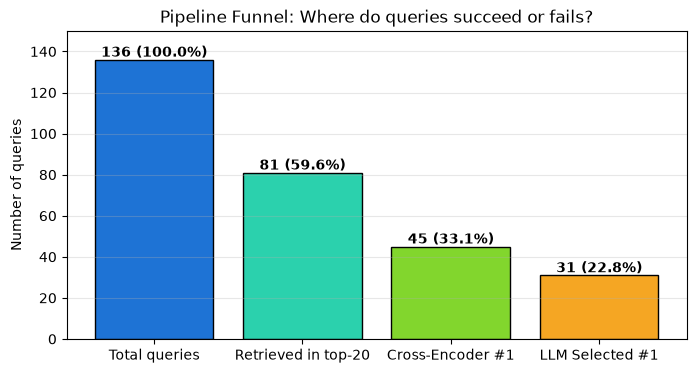

In [22]:
stages = ['Total queries', 'Retrieved in top-20', 'Cross-Encoder #1', 'LLM Selected #1']
counts = [n_total, retrieved_count, ce_hits, llm_hits]
colors = ["#1e73d5", "#2bd1ad", "#82d62d", '#f5a623']

plt.figure(figsize=(8, 4))
bars = plt.bar(stages, counts, color=colors, edgecolor='black')
plt.title('Pipeline Funnel: Where do queries succeed or fails?')
plt.ylabel('Number of queries')
plt.grid(axis='y', alpha=0.3)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval} ({yval/n_total*100:.1f}%)", ha='center', fontweight='bold')
plt.ylim(0, 150)
plt.show()

* 55 queries failed before any Reranker or LLM could even touch them.
    * The main area for improvement is enhancing the initial search phase.

* The actual performance of the Cross-Encoder was 55.6%.
    * It placed the correct product first 45 times out of 81.
    * In only 36 of the queries (26.5% of the total), the correct product ranked between 2-20nd.

* The LLM missed 14 matches that the Cross-Encoder found.
    * This is directly explained by previously observed hallucinations (16.2%) and overly cautious "none" responses (16.9%).

## Manual error categorization

Let’s take a direct look at the cases where the best model (Cross-Encoder) failed, and categorize them.

In [25]:
# pick out the top-1 predictions
ce_rank1 = reranked_top20[reranked_top20['rank'] == 1][['clean_query', 'product_number', 'clean_label']].rename(
    columns={'product_number': 'ce_top1_code', 'clean_label': 'ce_top1_label'}
)

# merge with dev queries
error_review = dev_queries.merge(ce_rank1, on='clean_query', how='left')
error_review['is_hit'] = [row['ce_top1_code'] in row['gold_product_number'] for _, row in error_review.iterrows()]

# find the rank of the gold product in the reranked top-20
gold_ranks = []
in_top20_list = []
for _, row in error_review.iterrows():
    q = row['clean_query']
    gold = row['gold_product_number']
    
    # get the reranked top-20 for this query
    q_reranked = reranked_top20[reranked_top20['clean_query'] == q]
    matching_ranks = q_reranked[q_reranked['product_number'].isin(gold)]['rank'].tolist()
    
    if len(matching_ranks) > 0:
        in_top20_list.append(True)
        gold_ranks.append(matching_ranks[0]) # best rank of the gold product
    else:
        in_top20_list.append(False)
        gold_ranks.append(np.nan)
error_review['in_top20'] = in_top20_list
error_review['gold_rank'] = gold_ranks


failures = error_review[~error_review['is_hit']].reset_index(drop=True)

print(f"Total failures in Cross-Encoder top-1: {len(failures)}")
print(f"Correct products in top-20: {(failures['in_top20'] == True).sum()} kpl")
print(f"Correct products not in top-20: {(failures['in_top20'] == False).sum()} kpl")


Total failures in Cross-Encoder top-1: 91
Correct products in top-20: 36 kpl
Correct products not in top-20: 55 kpl


In [28]:
# display the failures where the correct product was in the top-20
display(failures[failures['in_top20'] == True][['clean_query', 'product_label', 'ce_top1_label', 'gold_rank']])

,clean_query,product_label,ce_top1_label,gold_rank
4,ensiaputarvikkeet turvaleikkuri,TURVAVYÖLEIKKURI,turvaleikkuri patruunoille,2.0
5,henkilön suojaimet / työturvallisuus hengityks...,HENGITYKSENSUOJAIN CM3000 FFP2V,hengityksensuojain jedx 3971w ffp2 nr,8.0
6,henkilön suojaimet / työturvallisuus hengityks...,HENGITYKSENSUOJAIN FMH 4000 FFP3V,hengityksensuojain jedx 3972w ffp3 nr,4.0
7,henkilön suojaimet / työturvallisuus naamiosuo...,NAAMIOSUOJALASI ANDROMEDA,naamiosuojalasi bolle spectrum foam,12.0
10,henkilön suojaimet / työturvallisuus suojalasi...,SUOJALASI LIBRA OVERSPEC KIRKAS,suojalasi työvalaisin wurth 40w kirkas,6.0
14,"jakoavain 6"" c.v. 38041",JAKOAVAIN 6,jakoavain 6 swo,2.0
16,kaasusytytin 1695 348 9,KAASUSYTYTIN KUPPIMALLI,kaasusytytin turbo-lite,4.0
19,kemikaalit pesuainetiiviste 20 l,YLEISPESUAINE TP1000 20 LTR,würth cargo 20 l,6.0
20,kemikaalit puhdistusspray 500 ml,PUHDISTUSSPRAY 500 ML,puhdistusspray black edition 500 ml,2.0
25,kirvesmiehen vasara 16oz/450g st 1 rt,KIRVESMIEHENVASARA 16OZ PUTKIVARSI,kirvesmiehenvasara 16oz kokoteräs,2.0


In [29]:
# total failures where the correct product was not in the top-20
display(failures[failures['in_top20'] == False][['clean_query', 'product_label', 'ce_top1_label']])

,clean_query,product_label,ce_top1_label
0,11. akkuruuviväännin – 18 v,"AKKU LI-ION 18V/5,0AH M-CUBE W-CONNECT",konepaketti m-cube w-connect 18v maxi1
1,"7. akkuruuviväännin – 10,9 v",AKKUPORA BS12-A,akkuruuviväännin speede 2 vde
2,akkuporakone 18v ddf484t makita,"AKKUPORAVASARA ABH 18 COMPACT, 2X5.0AH",akkuporakone ddf485z 18v lxt runko
3,"askartelupuukko terä n. 100mm ""mora-tyylinen""",PUUKKO HIILITERÄS,senkkausterä sarj. 100-6pcs-11501390
8,henkilön suojaimet / työturvallisuus nahka / k...,YLEISKÄSINE SENSE 10,työkäs worker puoliv haljas/kangas 10
9,henkilön suojaimet / työturvallisuus nitriilik...,KERTAK NITRIILI ABENA CLASSIC 100KPL XS,asentajankäsine nitrile esd 9
11,henkilön suojaimet / työturvallisuus suojalasi...,SUOJALASI ARRAKIS KIRKAS,suojakypärä zenith x max sininen
12,"hienomek. ruuvitaltta 2,5x50 -1kpl","HIENOMEK. RUUVIMEISSELI 2,5X0,4MM ESD",vanttiruuvi 5x50
13,jakoavain 250mm slim,JAKOAVAIN 8 SWO,eristetty jakoavain 250mm vde 1000v
15,"jalkineet turvasaappaat, malli 1, normaali lesti",TURVAS STEPLITE EASYGRIP 36,turvaj sievi 52417 spider roller+ 38



The errors fall clearly into two categories based on their cause:

* Retrieval failure -> 55 instances (60,4%)
    * The right product was not in the top 20 searches at all.
    * Cross-Encoder or LLM could not even theoretically find the right product
    * to the report: The biggest bottleneck in the system is the initial search (Recall@20 = 59.6%). No reranker or LLM can ever achieve more than 60% Hit@1 accuracy until the initial search is improved.

* Reranking failure -> 36 instance (39,6%)
    * The correct product was among the candidates (ranked 2–20), but Cross-Encoder promoted another product to number 1.
    * to the report: Only these 36 cases can be "blamed" on Cross-Encoder. Here, the Cross-Encoder made a real comparison error between two or more products. However, these could contain multiple products that matched the search.

### Retrieval failure

In [30]:
ranking_fail_queries = df_funnel[df_funnel['in_hybrid_top20'] & ~df_funnel['ce_hit1']]['clean_query']
ranking_errors = []
for q in ranking_fail_queries:
    q_rows = reranked_top20[reranked_top20['clean_query'] == q]
    
    top1 = q_rows[q_rows['rank'] == 1].iloc[0]
    gold = q_rows[q_rows['is_hit'] == True].iloc[0]
    
    ranking_errors.append({
        'clean_query': q,
        'ce_top1_label': top1['clean_label'],
        'ce_top1_score': round(top1['reranker_score'], 3),
        'gold_label': gold['clean_label'],
        'gold_rank': int(gold['rank']),
        'gold_score': round(gold['reranker_score'], 3)
    })
df_ranking_errors = pd.DataFrame(ranking_errors)
print(f"Ranking failures count: {len(df_ranking_errors)}")

Ranking failures count: 36


In [31]:
pd.set_option('display.max_colwidth', None)
df_ranking_errors[['clean_query', 'ce_top1_label', 'gold_label', 'gold_rank']]

,clean_query,ce_top1_label,gold_label,gold_rank
0,ensiaputarvikkeet turvaleikkuri,turvaleikkuri patruunoille,turvavyöleikkuri,2
1,henkilön suojaimet / työturvallisuus hengityksensuojain ffp 2 nr d,hengityksensuojain jedx 3971w ffp2 nr,hengityksensuojain cm3000 ffp2v,8
2,henkilön suojaimet / työturvallisuus hengityksensuojain kokoontaitettava ffp3 nr d,hengityksensuojain jedx 3972w ffp3 nr,hengityksensuojain fmh 4000 ffp3v,4
3,henkilön suojaimet / työturvallisuus naamiosuojalasi kirkas,naamiosuojalasi bolle spectrum foam,naamiosuojalasi andromeda,12
4,henkilön suojaimet / työturvallisuus suojalasi kirkas,suojalasi työvalaisin wurth 40w kirkas,suojalasi terminator kirkas ja pussi,6
5,"jakoavain 6"" c.v. 38041",jakoavain 6 swo,jakoavain 6,2
6,kaasusytytin 1695 348 9,kaasusytytin turbo-lite,kaasusytytin kuppimalli,4
7,kemikaalit pesuainetiiviste 20 l,würth cargo 20 l,yleispesuaine tp1000 20 ltr,6
8,kemikaalit puhdistusspray 500 ml,puhdistusspray black edition 500 ml,puhdistusspray 500 ml,2
9,kirvesmiehen vasara 16oz/450g st 1 rt,kirvesmiehenvasara 16oz kokoteräs,kirvesmiehenvasara 16oz putkivarsi,2


### Ranking failure

In [32]:
retrieval_fail_queries = df_funnel[~df_funnel['in_hybrid_top20']]['clean_query']
retrieval_errors = []
for q in retrieval_fail_queries:
    q_rows = reranked_top20[reranked_top20['clean_query'] == q]
    gold_label = df_funnel[df_funnel['clean_query'] == q]['gold_label'].values[0]
    top1_label = q_rows[q_rows['rank'] == 1]['clean_label'].values[0] if not q_rows.empty else 'None'
    
    retrieval_errors.append({
        'clean_query': q,
        'gold_label': gold_label,
        'top1_offered': top1_label
    })
df_retrieval_errors = pd.DataFrame(retrieval_errors)
print(f"Retrieval failures count: {len(df_retrieval_errors)}")
df_retrieval_errors

Retrieval failures count: 55


,clean_query,gold_label,top1_offered
0,11. akkuruuviväännin – 18 v,"AKKU LI-ION 18V/5,0AH M-CUBE W-CONNECT",konepaketti m-cube w-connect 18v maxi1
1,"7. akkuruuviväännin – 10,9 v",AKKUPORA BS12-A,akkuruuviväännin speede 2 vde
2,akkuporakone 18v ddf484t makita,"AKKUPORAVASARA ABH 18 COMPACT, 2X5.0AH",akkuporakone ddf485z 18v lxt runko
3,"askartelupuukko terä n. 100mm ""mora-tyylinen""",PUUKKO HIILITERÄS,senkkausterä sarj. 100-6pcs-11501390
4,henkilön suojaimet / työturvallisuus nahka / kangaskäsine,YLEISKÄSINE SENSE 10,työkäs worker puoliv haljas/kangas 10
5,henkilön suojaimet / työturvallisuus nitriilikäsineet,KERTAK NITRIILI ABENA CLASSIC 100KPL XS,asentajankäsine nitrile esd 9
6,henkilön suojaimet / työturvallisuus suojalasi sininen,SUOJALASI ARRAKIS KIRKAS,suojakypärä zenith x max sininen
7,"hienomek. ruuvitaltta 2,5x50 -1kpl","HIENOMEK. RUUVIMEISSELI 2,5X0,4MM ESD",vanttiruuvi 5x50
8,jakoavain 250mm slim,JAKOAVAIN 8 SWO,eristetty jakoavain 250mm vde 1000v
9,"jalkineet turvasaappaat, malli 1, normaali lesti",TURVAS STEPLITE EASYGRIP 36,turvaj sievi 52417 spider roller+ 38


## Recommendations

### Multi-Stage Reranking